In [1]:
"""
Taula elevadora: variació de theta, y i les seves derivades en funció de la
posició x del punt A.

    x = 2L cos(theta),   y = 2L sin(theta),   0 < x < 2L

Amb una velocitat de l'actuador xdot constant (xddot = 0), es veu com la
mateixa entrada produeix velocitats i acceleracions molt diferents segons la
posició, i com tot divergeix quan x -> 2L (theta -> 0, configuració singular).
"""

"\nTaula elevadora: variació de theta, y i les seves derivades en funció de la\nposició x del punt A.\n\n    x = 2L cos(theta),   y = 2L sin(theta),   0 < x < 2L\n\nAmb una velocitat de l'actuador xdot constant (xddot = 0), es veu com la\nmateixa entrada produeix velocitats i acceleracions molt diferents segons la\nposició, i com tot divergeix quan x -> 2L (theta -> 0, configuració singular).\n"

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
# ---------------------------------------------------------------- paràmetres
L = 0.5        # m, longitud de mitja barra
xdot =  0.10   # m/s, velocitat del punt A (negativa: A s'acosta, la taula puja)
xddot = 0.0    # m/s^2, acceleració del punt A
th_lim = 25 # graus, angle a partir del qual comença una alta no-linealitat
x_lim = 2*L * np.cos(np.radians(th_lim)) # 0.90 * 2 * L   # a partir d'aquí s'ombreja la zona propera a la singularitat
lim_vel = 4.0  # factor per retallar l'eix vertical prop de la singularitat

In [4]:
# ---------------------------------------------------------------- càlcul
x = np.linspace(0.01 * 2 * L, 0.995 * 2 * L, 800)
w = np.sqrt(4 * L**2 - x**2)          # = 2L sin(theta) = y

In [5]:
theta = np.arccos(x / (2 * L))
y = w
thetadot = -xdot / w
ydot = -x * xdot / w
thetaddot = -xddot / w - x * xdot**2 / w**3
yddot = -x * xddot / w - 4 * L**2 * xdot**2 / w**3

In [6]:
# ---------------------------------------------------------------- estil
C_THETA = "#2a78d6"   # blau  (columna theta)
C_Y = "#eb6834"       # taronja (columna y)
INK = "#0b0b0b"
INK2 = "#52514e"
GRID = "#e4e3df"

In [7]:
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
    "font.size": 10,
    "axes.edgecolor": INK2,
    "axes.labelcolor": INK,
    "xtick.color": INK2,
    "ytick.color": INK2,
    "axes.spines.top": False,
    "axes.spines.right": False,
})

In [8]:
files = [
    (np.degrees(theta), r"$\theta$ [$^\circ$]", y, r"$y$ [m]"),
    (thetadot, r"$\dot\theta$ [rad/s]", ydot, r"$\dot y$ [m/s]"),
    (thetaddot, r"$\ddot\theta$ [rad/s$^2$]", yddot, r"$\ddot y$ [m/s$^2$]"),
]

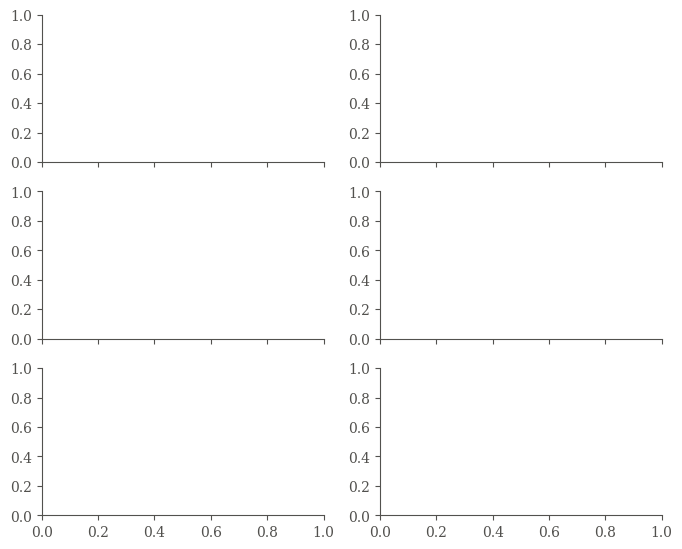

In [9]:
fig, axs = plt.subplots(3, 2, figsize=(8, 6.5), sharex=True)

In [10]:
for fila, (v1, et1, v2, et2) in enumerate(files):
    for col, (v, et, c) in enumerate([(v1, et1, C_THETA), (v2, et2, C_Y)]):
        ax = axs[fila, col]
        ax.axvspan(x_lim, 2 * L, color=GRID, lw=0, zorder=0)
        ax.axhline(0, color=INK2, lw=0.6, zorder=1)
        ax.plot(x, v, color=c, lw=2, zorder=3)
        ax.set_ylabel(et)
        ax.grid(True, color=GRID, lw=0.6, zorder=0)
        ax.set_xlim(0, 2 * L)

        # Retalla l'eix vertical prop de la singularitat perquè es vegi la resta
        if fila > 0:
            ref = np.abs(v[x < x_lim]).max()
            lo, hi = min(v.min(), 0.0), max(v.max(), 0.0)   # el zero sempre visible
            ax.set_ylim(max(lo, -lim_vel * ref) * 1.05 - 0.02 * ref,
                        min(hi, lim_vel * ref) * 1.05 + 0.02 * ref)

In [11]:
for ax in axs[-1]:
    ax.set_xlabel(r"$x$ [m]")

In [12]:
ax = axs[0, 1]
punt = (x_lim + 0.25 * (2 * L - x_lim), 0.2 * ax.get_ylim()[1])   # dins la zona, sota la corba
ax.annotate(
    "zona un 10% propera\na la singularitat\n"
    + rf"($x > {x_lim:.1f}$ m, $\theta < {th_lim:.0f}^\circ$)",
    xy=punt, xytext=(x_lim - 0.06, punt[1]),
    fontsize=9, color=INK2, ha="right", va="center",
    arrowprops=dict(arrowstyle="-", color=INK2, lw=0.8,
                    shrinkA=4, shrinkB=0, relpos=(1, 0.5)))
ax.plot(*punt, "o", ms=4, color=INK2, zorder=5)

Taula elevadora, $L=0.5$ m, $\dot x=0.1$ m/s constant.


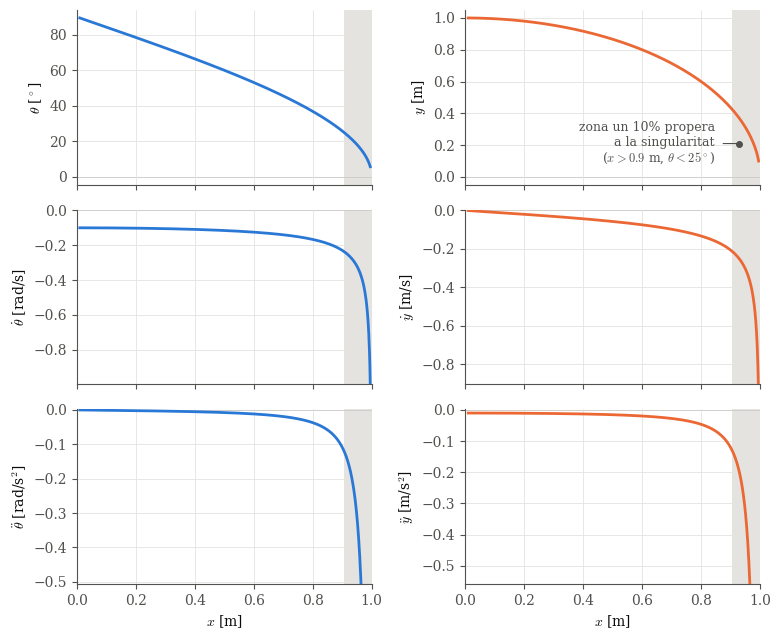

In [13]:
text_caption = rf"Taula elevadora, $L={L}$ m, $\dot x={xdot}$ m/s constant."
# fig.suptitle( text_caption,  color=INK, fontsize=11)
fig.tight_layout()
# fig.savefig("TME_ee_taula_elevadora.pdf")
# fig.savefig("taula_elevadora.png", dpi=150)
print(text_caption)
fig